In [1]:
import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, f1_score

train_df = pd.read_csv(
    "../../data/processed/selected_training.csv"
)

test_df = pd.read_csv(
    "../../data/processed/selected_testing.csv"
)


In [2]:
from sklearn.model_selection import train_test_split

X = train_df.drop(columns=["label", "attack_cat"])

y = train_df["attack_cat"].fillna("Normal")
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

Training: (98869, 43)
Validation: (24718, 43)


In [3]:
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical:", numeric_features)
print("Categorical:", categorical_features)

Numerical: ['id', 'dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']
Categorical: ['proto', 'service', 'state']


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

# Even though you currently have no missing values, the imputers make the pipeline more robust. 

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

In [5]:
print("Preprocessor:", preprocessor)
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

Preprocessor: ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median'))]),
                                 ['id', 'dur', 'spkts', 'dpkts', 'sbytes',
                                  'dbytes', 'rate', 'sttl', 'dttl', 'sload',
                                  'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt',
                                  'sjit', 'djit', 'swin', 'stcpb', 'dtcpb',
                                  'dwin', 'tcprtt', 'synack', 'ackdat', 'smean',
                                  'dmean', 'trans_depth', 'response_body_len',
                                  'ct_srv_src', 'ct_state_ttl', ...]),
                                ('categorical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(fill_value='Unknown',
                                                           

## Training the baseline model 

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, f1_score

# Create baseline model
baseline_model = DummyClassifier(
    strategy="most_frequent"
)

# Train the baseline
baseline_model.fit(X_train, y_train)

# Predict on validation data
y_pred_base = baseline_model.predict(X_val)

# Evaluate
print(
    "Baseline Macro F1:",
    f1_score(y_val, y_pred_base, average="macro")
)

print(
    classification_report(
        y_val,
        y_pred_base,
        zero_division=0
    )
)

Baseline Macro F1: 0.10394045696679473
              precision    recall  f1-score   support

    Analysis       0.00      0.00      0.00       400
    Backdoor       0.00      0.00      0.00       349
         DoS       0.00      0.00      0.00      2453
    Exploits       0.00      0.00      0.00      6679
     Fuzzers       0.00      0.00      0.00      3637
      Normal       0.45      1.00      0.62     11200

    accuracy                           0.45     24718
   macro avg       0.08      0.17      0.10     24718
weighted avg       0.21      0.45      0.28     24718



## Training the actual ML model

In [7]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])

decision_tree.fit(X_train, y_train)

y_pred_dt = decision_tree.predict(X_val)

print("Decision Tree Macro F1:",
      f1_score(y_val, y_pred_dt, average="macro"))

print(classification_report(y_val, y_pred_dt, zero_division=0))

Decision Tree Macro F1: 0.5749809688979841
              precision    recall  f1-score   support

    Analysis       0.23      0.23      0.23       400
    Backdoor       0.23      0.19      0.21       349
         DoS       0.38      0.41      0.40      2453
    Exploits       0.77      0.76      0.76      6679
     Fuzzers       0.87      0.85      0.86      3637
      Normal       0.99      0.99      0.99     11200

    accuracy                           0.83     24718
   macro avg       0.58      0.57      0.57     24718
weighted avg       0.83      0.83      0.83     24718



## Train Random Forest

In [8]:
from sklearn.ensemble import RandomForestClassifier

random_forest = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest.fit(X_train, y_train)

y_pred_rf = random_forest.predict(X_val)

print("Random Forest Macro F1:",
      f1_score(y_val, y_pred_rf, average="macro"))

print(classification_report(y_val, y_pred_rf, zero_division=0))

Random Forest Macro F1: 0.5639166496539884
              precision    recall  f1-score   support

    Analysis       0.23      0.20      0.21       400
    Backdoor       0.20      0.15      0.17       349
         DoS       0.40      0.37      0.39      2453
    Exploits       0.77      0.81      0.79      6679
     Fuzzers       0.82      0.87      0.85      3637
      Normal       0.99      0.97      0.98     11200

    accuracy                           0.83     24718
   macro avg       0.57      0.56      0.56     24718
weighted avg       0.82      0.83      0.83     24718



In [9]:
from sklearn.ensemble import RandomForestClassifier

random_forest = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest.fit(X_train, y_train)

y_pred_rf = random_forest.predict(X_val)

print("Random Forest Macro F1:",
      f1_score(y_val, y_pred_rf, average="macro"))

print(classification_report(
    y_val,
    y_pred_rf,
    zero_division=0
))

Random Forest Macro F1: 0.5639166496539884
              precision    recall  f1-score   support

    Analysis       0.23      0.20      0.21       400
    Backdoor       0.20      0.15      0.17       349
         DoS       0.40      0.37      0.39      2453
    Exploits       0.77      0.81      0.79      6679
     Fuzzers       0.82      0.87      0.85      3637
      Normal       0.99      0.97      0.98     11200

    accuracy                           0.83     24718
   macro avg       0.57      0.56      0.56     24718
weighted avg       0.82      0.83      0.83     24718



In [10]:
results = pd.DataFrame({
    "Model": [
        "Dummy Classifier",
        "Decision Tree",
        "Random Forest"
    ],
    "Macro F1": [
        f1_score(y_val, y_pred_base, average="macro"),
        f1_score(y_val, y_pred_dt, average="macro"),
        f1_score(y_val, y_pred_rf, average="macro")
    ]
})

print(results.sort_values(
    by="Macro F1",
    ascending=False
))

              Model  Macro F1
1     Decision Tree  0.574981
2     Random Forest  0.563917
0  Dummy Classifier  0.103940


In [11]:
# class weighting
balanced_tree = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

balanced_tree.fit(X_train, y_train)

y_pred_balanced = balanced_tree.predict(X_val)

balanced_tree_f1 = f1_score(
    y_val,
    y_pred_balanced,
    average="macro"
)

print("Balanced Decision Tree Macro F1:", balanced_tree_f1)

print(classification_report(
    y_val,
    y_pred_balanced,
    zero_division=0
))

Balanced Decision Tree Macro F1: 0.5727237253612882
              precision    recall  f1-score   support

    Analysis       0.22      0.22      0.22       400
    Backdoor       0.22      0.18      0.20       349
         DoS       0.38      0.42      0.40      2453
    Exploits       0.77      0.76      0.77      6679
     Fuzzers       0.88      0.85      0.86      3637
      Normal       0.99      0.99      0.99     11200

    accuracy                           0.83     24718
   macro avg       0.58      0.57      0.57     24718
weighted avg       0.83      0.83      0.83     24718



In [12]:
# balanced random forest 
balanced_forest = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

balanced_forest.fit(X_train, y_train)

y_pred_balanced_rf = balanced_forest.predict(X_val)

balanced_forest_f1 = f1_score(
    y_val,
    y_pred_balanced_rf,
    average="macro"
)

print("Balanced Random Forest Macro F1:", balanced_forest_f1)

print(classification_report(
    y_val,
    y_pred_balanced_rf,
    zero_division=0
))

Balanced Random Forest Macro F1: 0.5600644110764267
              precision    recall  f1-score   support

    Analysis       0.21      0.18      0.19       400
    Backdoor       0.21      0.15      0.18       349
         DoS       0.40      0.37      0.38      2453
    Exploits       0.77      0.81      0.79      6679
     Fuzzers       0.82      0.87      0.84      3637
      Normal       0.99      0.96      0.98     11200

    accuracy                           0.83     24718
   macro avg       0.56      0.56      0.56     24718
weighted avg       0.82      0.83      0.82     24718



In [13]:
# AdaBoost using a shallow Decision Tree as its base estimator
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, classification_report

adaboost_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=2),
        n_estimators=50,
        learning_rate=0.5,
        random_state=42
    ))
])

adaboost_model.fit(X_train, y_train)

y_pred_ada = adaboost_model.predict(X_val)

print(
    "AdaBoost Macro F1:",
    f1_score(y_val, y_pred_ada, average="macro")
)

print(classification_report(
    y_val,
    y_pred_ada,
    zero_division=0
))

AdaBoost Macro F1: 0.4059111854711556
              precision    recall  f1-score   support

    Analysis       1.00      0.00      0.00       400
    Backdoor       0.00      0.00      0.00       349
         DoS       0.04      0.00      0.00      2453
    Exploits       0.63      0.93      0.75      6679
     Fuzzers       0.68      0.79      0.73      3637
      Normal       0.97      0.92      0.94     11200

    accuracy                           0.78     24718
   macro avg       0.55      0.44      0.41     24718
weighted avg       0.73      0.78      0.74     24718



In [14]:
# deeper base tree with AdaBoost.
adaboost_deep = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=3),
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    ))
])

adaboost_deep.fit(X_train, y_train)

y_pred_ada_deep = adaboost_deep.predict(X_val)

print(
    "AdaBoost Deep Macro F1:",
    f1_score(y_val, y_pred_ada_deep, average="macro")
)

print(classification_report(
    y_val,
    y_pred_ada_deep,
    zero_division=0
))

AdaBoost Deep Macro F1: 0.4921885438103131
              precision    recall  f1-score   support

    Analysis       0.72      0.12      0.20       400
    Backdoor       0.64      0.11      0.19       349
         DoS       0.29      0.03      0.05      2453
    Exploits       0.64      0.94      0.76      6679
     Fuzzers       0.75      0.83      0.79      3637
      Normal       0.99      0.93      0.96     11200

    accuracy                           0.80     24718
   macro avg       0.67      0.49      0.49     24718
weighted avg       0.78      0.80      0.77     24718



In [15]:
#  gradient boosting
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, classification_report

gradient_boosting = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gradient_boosting.fit(X_train, y_train)

y_pred_gb = gradient_boosting.predict(X_val)

print(
    "Gradient Boosting Macro F1:",
    f1_score(y_val, y_pred_gb, average="macro")
)

print(classification_report(
    y_val,
    y_pred_gb,
    zero_division=0
))

Gradient Boosting Macro F1: 0.5623182758150396
              precision    recall  f1-score   support

    Analysis       0.78      0.17      0.29       400
    Backdoor       0.71      0.16      0.27       349
         DoS       0.46      0.13      0.21      2453
    Exploits       0.68      0.94      0.79      6679
     Fuzzers       0.85      0.86      0.86      3637
      Normal       0.99      0.96      0.97     11200

    accuracy                           0.83     24718
   macro avg       0.74      0.54      0.56     24718
weighted avg       0.82      0.83      0.81     24718



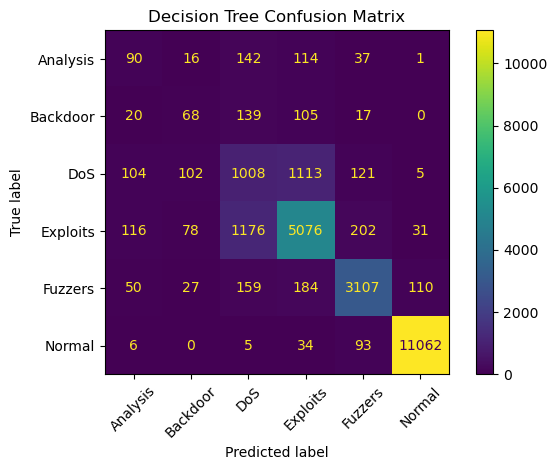

In [16]:
# inspecting the confusion matrix for our best Decision Tree and Gradient Boosting models.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Decision Tree
cm_dt = confusion_matrix(
    y_val,
    y_pred_dt,
    labels=decision_tree.named_steps["classifier"].classes_
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=decision_tree.named_steps["classifier"].classes_
).plot(xticks_rotation=45)

plt.title("Decision Tree Confusion Matrix")
plt.tight_layout()
plt.show()

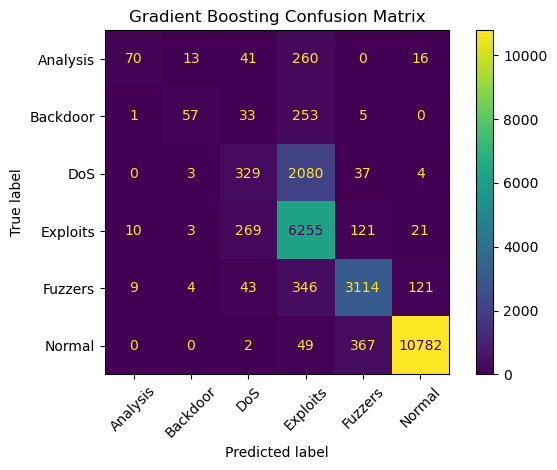

In [17]:
cm_gb = confusion_matrix(
    y_val,
    y_pred_gb,
    labels=gradient_boosting.named_steps["classifier"].classes_
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_gb,
    display_labels=gradient_boosting.named_steps["classifier"].classes_
).plot(xticks_rotation=45)

plt.title("Gradient Boosting Confusion Matrix")
plt.tight_layout()
plt.show()

In [18]:
# to understand which features the Decision Tree uses when making predictions.
import pandas as pd

dt_classifier = decision_tree.named_steps["classifier"]

feature_names = (
    decision_tree.named_steps["preprocessor"]
    .get_feature_names_out()
)

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": dt_classifier.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

print(feature_importance.head(20))

                        feature  importance
0                   numeric__id    0.563679
4               numeric__sbytes    0.071504
38          numeric__ct_srv_dst    0.060858
24               numeric__smean    0.052532
7                 numeric__sttl    0.022378
158      categorical__proto_udp    0.021289
5               numeric__dbytes    0.017084
25               numeric__dmean    0.016610
172      categorical__service_-    0.013846
33      numeric__ct_dst_src_ltm    0.011084
9                numeric__sload    0.008685
1                  numeric__dur    0.008495
28          numeric__ct_srv_src    0.007559
14              numeric__dinpkt    0.006950
10               numeric__dload    0.006431
6                 numeric__rate    0.006320
37          numeric__ct_src_ltm    0.006189
13              numeric__sinpkt    0.005965
27   numeric__response_body_len    0.005761
22              numeric__synack    0.005528


In [19]:
# We will train another Decision Tree using exactly the same training and validation split, but without the id feature.
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_features_no_id = [
    col for col in numeric_features if col != "id"
]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_no_id = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features_no_id),
    ("categorical", categorical_transformer, categorical_features)
])

In [20]:
decision_tree_no_id = Pipeline([
    ("preprocessor", preprocessor_no_id),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

decision_tree_no_id.fit(X_train, y_train)

y_pred_no_id = decision_tree_no_id.predict(X_val)

f1_no_id = f1_score(
    y_val,
    y_pred_no_id,
    average="macro"
)

print("Decision Tree without ID Macro F1:", f1_no_id)

print(classification_report(
    y_val,
    y_pred_no_id,
    zero_division=0
))

Decision Tree without ID Macro F1: 0.5096947027566188
              precision    recall  f1-score   support

    Analysis       0.50      0.15      0.23       400
    Backdoor       0.52      0.10      0.17       349
         DoS       0.31      0.27      0.29      2453
    Exploits       0.68      0.80      0.73      6679
     Fuzzers       0.76      0.68      0.71      3637
      Normal       0.92      0.93      0.92     11200

    accuracy                           0.77     24718
   macro avg       0.61      0.49      0.51     24718
weighted avg       0.76      0.77      0.76     24718



In [21]:
# tunning the decision tree by introducing the hyperparameter
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

dt_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

param_grid = {
    "classifier__max_depth": [10, 15, 20, None],
    "classifier__min_samples_split": [2, 10, 20],
    "classifier__min_samples_leaf": [1, 5, 10],
    "classifier__criterion": ["gini", "entropy"]
}

grid_search = GridSearchCV(
    dt_pipeline,
    param_grid,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV Macro F1:", grid_search.best_score_)

Fitting 3 folds for each of 72 candidates, totalling 216 fits
Best parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 15, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}
Best CV Macro F1: 0.6026177660239759


In [22]:
# evaluating the tuned model on the the validation set 
best_dt = grid_search.best_estimator_

y_pred_tuned_dt = best_dt.predict(X_val)

print(
    "Tuned Decision Tree Macro F1:",
    f1_score(y_val, y_pred_tuned_dt, average="macro")
)

print(classification_report(
    y_val,
    y_pred_tuned_dt,
    zero_division=0
))

Tuned Decision Tree Macro F1: 0.6031643152214534
              precision    recall  f1-score   support

    Analysis       0.63      0.22      0.33       400
    Backdoor       0.70      0.18      0.29       349
         DoS       0.45      0.32      0.37      2453
    Exploits       0.71      0.87      0.79      6679
     Fuzzers       0.89      0.84      0.87      3637
      Normal       0.98      0.98      0.98     11200

    accuracy                           0.84     24718
   macro avg       0.73      0.57      0.60     24718
weighted avg       0.83      0.84      0.83     24718

